# tobac workflow on observations - INTERACTIVE
- **see 27_apply_tobac_OBS for version used for the final calculations!**
- what this nbook does:
    - Nasa tb, IMERG and CCIC loaded, clip to tropics, resampled to IMERG grid
    - tobac application:
        - anvils 
            - detect on Tb (Nasa-Tb)
            - segmentate on Tb 
            - bulk stats of IWP (CCIC)
            - bulk stats on tb
            - additional stats (area)
            - potenially save the mask & features
        - precip cells
            - detect on precip
            - segmentate on precip
            - bulk stats of Precip (precip)
            - additional stats (area)
            - potenially save the mask & features
        - merge anvil properties to cell features table to df_cell_combined
        - add additional columns
        - save **df_cell_combined**
        - some plots to evaluate anvil and precip cell segmentation
- input:
    - Nasa Tb, Imerg, CCIC 
    - date YYYY-MM-DD-HHMM
- adapt:
    - output dir for seg results data
    - tobac parameters for detection and segmentation
    - date
- output: 
    - combined precip features df with anvil properties and further columns (FINAL PRODUCT)
    - plots

In [1]:
import warnings

# ignore general categories
for cat in [FutureWarning, RuntimeWarning, UserWarning]:
    warnings.filterwarnings("ignore", category=cat)

# ignore specific repeated messages
for msg in [
    "pyproj unable to set PROJ database path",
    "As of v1.6.0, segmentation with time length 1",
    "Using DEFAULT_SPHERICAL_EARTH_RADIUS"
]:
    warnings.filterwarnings("ignore", message=msg)

In [2]:
import numpy as np
import xarray as xr
import os

from pathlib import Path

# Import tobac itself:
import tobac
import tobac.utils

print("using tobac version", str(tobac.__version__))

import iris

# plotting
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import seaborn as sns

# load tools
import sys 
sys.path.append("../tools")
import handle_OBS_data

from defs_application import georegions 
import use_tobac
import plots_mapping

using tobac version 1.6.3


In [3]:
os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"

# arguments

In [4]:
# set date
#date = "2020-06-06-2100"
#date = sys.argv[1]

# manual adaption for launcher if outputs shoul db

# threshold_anvils
detection_threshold_anvil = 225 # K,
multi_detection_thresholds_anvil = [225] #K
segmentation_threshold_anvil = 241 # K 

# threhold precip
detection_threshold_cell = 10 # mm/h
multi_detection_thresholds_cell = [10] # mm/h
segmentation_threshold_cell = 10 # mm/h

# build a descriptive tag from parameters
param_tag = f"anvil_detectthres{detection_threshold_anvil}_seg{segmentation_threshold_anvil}_cell_detectthres{detection_threshold_cell}_seg{segmentation_threshold_cell}"
#param_tag



if "launcher" in sys.argv[0]: 
    date = "2023-06-06-1800"
    interactive =True
    saveoutputs = True
    savedir = Path("../output/apply_seg_new/apply_OBS_with_mask_from_nbook") # second_tune_OBS tobactryoutsdata_OBS

else: 
    date = sys.argv[1]
    interactive = False
    saveoutputs = True
    savedir = Path("../output/second_tune_OBS") / param_tag #apply/apply_OBS_with_mask
    

print(date)


2023-06-06-1800


In [5]:
############# ANVILS ############
# detection para (Tb)
feature_detection_params_anvil = dict()
feature_detection_params_anvil["threshold"] = multi_detection_thresholds_anvil
feature_detection_params_anvil["target"] = "minimum"
feature_detection_params_anvil["position_threshold"] = "weighted_diff"
feature_detection_params_anvil["PBC_flag"]='hdim_2'

# Gaussian smoothing before detection
feature_detection_params_anvil["sigma_threshold"] =  0.5 

# from below 
dX = 11119.492664455873
dxy =  dX 
# minimum number of pixels below threshold_anvil
#feature_detection_params_anvil["n_min_threshold"] = 3 # one pixel approx 10km * 10km = 100km2

# minimum pixel distance to next feature
feature_detection_params_anvil["min_distance"]= dxy*20  # mcs ICON trakcing example *4 => aber wir haben geresamplet zu 11 x 11km 

In [6]:
############# CELLS ############

# detection para (Tb)
feature_detection_params_cell = dict()
feature_detection_params_cell["threshold"] = multi_detection_thresholds_cell
feature_detection_params_cell["target"] = "maximum"
feature_detection_params_cell["position_threshold"] = "weighted_diff"
feature_detection_params_cell["PBC_flag"]='hdim_2'



# Gaussian smoothing before detection
feature_detection_params_cell["sigma_threshold"] = 0.05  
#feature_detection_params_cell["n_min_threshold"] = 3 # brueck


In [7]:

# create main directory
savedir.mkdir(parents=True, exist_ok=True)

# define subdirectories
subdirs = [
    #"cell_features",
    "anvil_features",
    "cell_features_combined",
    "combi_mask",
    "plots"
]

# create all subdirectories
for sub in subdirs:
    (savedir / sub).mkdir(parents=True, exist_ok=True)

# plots dir
plots_dir = savedir / "plots"

# load data
- load tb, precip, iwp
- crop to tropical belt, allign coordiate logic
- resmaple to imerg data so everything has same resolution (for bulk statiustics needed) 

In [8]:
# combi function   
tb = handle_OBS_data.load_calc_clean_mean_tb(date, buffer = 32, min_images= 5)
precip = handle_OBS_data.load_calc_clean_mean_imerg(date, buffer = 30, min_images= 5)
iwp = handle_OBS_data.load_calc_clean_mean_ccic(date, buffer = 32, min_images= 5)

# resample (data, precip)
tb = handle_OBS_data.resample_grids(tb,precip)   # resampling to imerg ref grid => precip data is +- 30° => automatically cropped 
iwp = handle_OBS_data.resample_grids(iwp,precip)  



QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

Tb data loaded for 2023-06-06-1800, if applicable both images returned, cropped, 'Tb' selected, longitude/latitude rename, assigned attrs,drop timedim


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

...

IMERG data loaded for 2023-06-06-1600, cleaned, cropped, 'precipitation' selected, longitude/latitude rename, assigned attrs,drop timedim


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

IMERG data loaded for 2023-06-06-1530, cleaned, cropped, 'precipitation' selected, longitude/latitude rename, assigned attrs,drop timedim
CCIC data loaded for 2023-06-06-1800, if applicable both images returned, cleaned, cropped, 'tiwp' selected, longitude/latitude rename, assigned attrs, drop timedim
CCIC data loaded for 2023-06-06-1700, if applicable both images returned, cleaned, cropped, 'tiwp' selected, longitude/latitude rename, assigned attrs, drop timedim
CCIC data loaded for 2023-06-06-1600, if applicable both images returned, cleaned, cropped, 'tiwp' selected, longitude/latitude rename, assigned attrs, drop timedim
CCIC data loaded for 2023-06-06-1500, if applicable both images returned, cleaned, cropped, 'tiwp' selected, longitude/latitude rename, assigned attrs, drop timedim


# equivalent grid size in meters

In [9]:
# # IMERG resolution

# dlon = 0.1   # degrees
# dlat = 0.1   # degrees

# lat0 = precip.latitude.mean().item()   

# R_earth = 6371e3

# dlambda = np.deg2rad(dlon)
# dphi     = np.deg2rad(dlat)
# phi0     = np.deg2rad(lat0)

# dA = R_earth**2 * np.cos(phi0) * dlambda * dphi
# dX = np.sqrt(dA)

# dX
#dX = 11119.492664455873

# Prepare Data
- convert the dataset into an Iris Cube (which is taken as tobac input)


In [10]:
# to iris cubes
tb_iris = tb.to_iris()
precip_iris = precip.to_iris()
iwp_iris = iwp.to_iris()


# expand time dim for tobac input (collapsed in the loading functions)
# import iris
tb_iris = iris.util.new_axis(tb_iris, scalar_coord='time')
precip_iris = iris.util.new_axis(precip_iris, scalar_coord='time')
iwp_iris = iris.util.new_axis(iwp_iris, scalar_coord='time')


# add iwp layer

In [11]:

# Parse the string into a datetime object
from datetime import datetime, timedelta

dt = datetime.strptime(date, '%Y-%m-%d-%H%M')
dt_minus_3h = dt - timedelta(hours=3)
date_previous = dt_minus_3h.strftime('%Y-%m-%d-%H%M')

# load data
# data selection
vlist_tend= ["qsvi","clivi","qgvi","crs"]


# select timestamp and variables
iwp = handle_OBS_data.load_calc_clean_mean_ccic(date_previous, buffer = 32, min_images= 5)
iwp = handle_OBS_data.resample_grids(iwp,precip)  

# prepare data
# to iris cubes
iwp_iris_previous = iwp.to_iris()

# # expand time dim for tobac input (collapsed in the loading functions)
iwp_iris_previous = iris.util.new_axis(iwp_iris_previous, scalar_coord='time')



#####################
##### iwp tendency calc
# Remove time coord from both before arithmetic (or equalize them)
iwp_iris_previous_notime = iwp_iris_previous.copy()
iwp_iris_previous_notime.remove_coord('time')

iwp_iris_notime = iwp_iris.copy()
iwp_iris_notime.remove_coord('time')

# actual calc
dtiwp = (iwp_iris_notime - iwp_iris_previous_notime) / 3  # d iwp = kg/m2 per 3h => divided by 3 for hourly tendency
# positive
dtiwp.data = np.where(dtiwp.data > 0, dtiwp.data, 0)

# Reattach the *current* timestamp's time coord to the result
# after subtraction, dtiwp already has the right shape (time_dim, lat, lon)
dtiwp.add_dim_coord(iwp_iris.coord('time'), 0)  # bind as DIM coord on dim 0, not a new axis


# rename so bulk stats putput is nice 
dtiwp.rename("dtiwp")          # sets long_name -> shows as "dtiwp" instead of "Unknown"
dtiwp.units = "kg m-2 h-1"     # correct units after the /3 (per-hour rate)
dtiwp.var_name = "dtiwp"

#dtiwp

# # as a side thing bc of added iwp values on cell mask
iwp_iris.rename("iwp")          # sets long_name -> shows as "dtiwp" instead of "Unknown"
iwp_iris.var_name = "iwp"

# dtiwp

CCIC data loaded for 2023-06-06-1500, if applicable both images returned, cleaned, cropped, 'tiwp' selected, longitude/latitude rename, assigned attrs, drop timedim
CCIC data loaded for 2023-06-06-1400, if applicable both images returned, cleaned, cropped, 'tiwp' selected, longitude/latitude rename, assigned attrs, drop timedim
CCIC data loaded for 2023-06-06-1300, if applicable both images returned, cleaned, cropped, 'tiwp' selected, longitude/latitude rename, assigned attrs, drop timedim
CCIC data loaded for 2023-06-06-1200, if applicable both images returned, cleaned, cropped, 'tiwp' selected, longitude/latitude rename, assigned attrs, drop timedim


# 1. Anvil detection and segmentation
## 1.1. tobac detection on Tb image
- use multiple threshold_anvil on BT data
- from here on: same workflow for ICON and OBS

### Perform feature detection

In [12]:
# Perform feature detection:
print('starting anvil feature detection')
features = tobac.feature_detection.feature_detection_multithreshold(
    tb_iris, dxy, **feature_detection_params_anvil
)

print('anvil feature detection performed')

starting anvil feature detection
anvil feature detection performed


##  1.2. Segmentation of Anvils (on BT)
- first filter!

### Filter results

In [13]:
#filter for thres
filtered_features = features[features["threshold_value"] <= detection_threshold_anvil]

In [14]:
print(features["hdim_2"].values.flags.writeable)
print(filtered_features["hdim_2"].values.flags.writeable)

True
True


### Set segmentation parameters

In [15]:
segmentation_params_anvil = dict()
segmentation_params_anvil["method"] = "watershed"
segmentation_params_anvil["threshold"] = segmentation_threshold_anvil
segmentation_params_anvil["target"] = "minimum"
segmentation_params_anvil["PBC_flag"]='hdim_2'

### perform segmentation

In [16]:
# import time
# t0 = time.time()
# # Perform segmentation:

print('Starting anvil segmentation.')
segmentation_mask_anvil, segmentation_features_anvil = tobac.segmentation.segmentation(
    filtered_features, tb_iris, dxy=dxy, **segmentation_params_anvil
)
print('segmentation anvil performed')

# t1 = time.time()
# print(f'segmentation anvil performed in {t1 - t0:.1f}s')

Starting anvil segmentation.
segmentation anvil performed


## 1.3. bulk statistics as post processing

In [17]:
# calc bulk plus area
df_merged_anvil = use_tobac.add_bulk_stats_anvil(segmentation_features_anvil, segmentation_mask_anvil, tb_iris,precip_iris,iwp_iris)


df_merged_anvil["d_eq"] = use_tobac.add_D_equ(df_merged_anvil["area"])

df_merged_anvil = use_tobac.add_bulk_stats(df_merged_anvil, segmentation_mask_anvil, dtiwp, stats=["sum"])

print('Bulk stats anvils calculated')

Bulk stats anvils calculated


In [18]:
#df_merged_anvil

## 1.4.  Save mask and final features

In [19]:
# save segmentation mask results
segmentation_mask_anvil_ds = xr.DataArray.from_iris(segmentation_mask_anvil)

In [20]:
#########################
#####    ANVILS   #######
#########################

# # save mask
# segmentation_mask_anvil_ds.to_netcdf(
#     savedir / "anvil_mask" / f'mask_anvil_segmentation_{param_tag}_{date}.nc',
#     mode='w',
#     encoding={"segmentation_mask": {"zlib": True, "complevel": 4}}
# )

# save features
# if saveoutputs: 
#     df_merged_anvil.to_hdf(
#         savedir / "anvil_features" / f'features_anvil_segmentation_inkl_bulkstats_{param_tag}_{date}.h5',
#         key='table', mode='w'
#     )
    
#     print('anvil features with bulk statistics saved')

# 2. Precip cell Detection and Segmentation on Precip image
- started with nbook from fabian warmworld 03
## 2.1. tobac detection on precip image

In [21]:
# Perform feature detection:
print('starting cell feature detection')
features_cell = tobac.feature_detection_multithreshold(precip_iris, dxy, **feature_detection_params_cell)
print('cell feature detection performed')

starting cell feature detection
cell feature detection performed


## 2.2. Precip cell segmentation
### filter features

In [22]:
#filter for thres
filtered_features_cell = features_cell[features_cell["threshold_value"] >= detection_threshold_cell]

### Set segmentation parameter

In [23]:
# Dictionary containing keyword arguments for segmentation step:
segmentation_params_cell={}
segmentation_params_cell['method']='watershed'
segmentation_params_cell['threshold']=segmentation_threshold_cell 
segmentation_params_cell["target"] = "maximum" 
segmentation_params_cell["PBC_flag"]='hdim_2'

### perfrom segmentation

In [24]:
# Perform segmentation:
print('Starting precip segmentation.')
segmentation_mask_cell, segmentation_features_cell =  tobac.segmentation.segmentation( #tobac.segmentation_2D(
    filtered_features_cell,precip_iris,dxy,**segmentation_params_cell)

print('segmentation precip performed')

Starting precip segmentation.
segmentation precip performed


## 2.3. Add bulk stats as post processing

In [25]:
import use_tobac

# calc bulk plus area
df_merged_cell = use_tobac.add_bulk_stats_cell(segmentation_features_cell, segmentation_mask_cell, precip_iris)


df_merged_cell["d_eq"] = use_tobac.add_D_equ(df_merged_cell["area"])

df_merged_cell = use_tobac.add_bulk_stats(
	    df_merged_cell, segmentation_mask_cell, dtiwp, stats=["sum"])
	
df_merged_cell = use_tobac.add_bulk_stats(
	    df_merged_cell, segmentation_mask_cell, iwp_iris, stats=["sum", "mean"])

#print('Bulk stats precips calculated')

In [26]:
#df_merged_cell

## 2.4. Save mask and final features

In [27]:
# save segmentation mask results
segmentation_mask_cell_ds = xr.DataArray.from_iris(segmentation_mask_cell)

# 3. save detect and seg parameters

In [28]:
if saveoutputs: 
    import json
    
    params_path = savedir / f'params_anvil_{param_tag}.json'
    
    if not params_path.exists():
        params_to_save = {
            "detection_threshold_anvil": detection_threshold_anvil,
            "detection_threshold_cell": detection_threshold_cell,
            "feature_detection_params_anvil":   feature_detection_params_anvil,
            "segmentation_params_anvil":    segmentation_params_anvil,
            "feature_detection_params_cell":   feature_detection_params_cell,
            "segmentation_params_cell":    segmentation_params_cell,
        }
        with open(params_path, 'w') as f:
            json.dump(params_to_save, f, indent=4)
        print(f"params saved for tag: {param_tag}")
    else:
        print(f"params already exist for tag: {param_tag}, skipping")


params saved for tag: anvil_detectthres225_seg241_cell_detectthres10_seg10


# 4. add Anvil charactistics to precip cell features
- use both segmentation masks
- all precip cells that have a anvil above them anywhere, anvil id covering the most precip cell pixels is selected


## 4.1 B (precip cell mask under anvil) 


In [29]:
# create one dataset for masks 
combi_mask = segmentation_mask_anvil_ds.to_dataset(name="segmentation_mask_anvil")
combi_mask["segmentation_mask_cell"]=segmentation_mask_cell_ds
combi_mask = combi_mask.squeeze()
combi_mask

# get cell ids (could also come from feature table)
cell_ids = np.unique(combi_mask["segmentation_mask_cell"].values)
cell_ids = cell_ids[cell_ids!=0]


cell_to_anvil = {}
diagnostic_anvils_per_cell = {}
for cell_id in cell_ids:
    # get anvil values only where this cell is
    anvil_vals = combi_mask["segmentation_mask_anvil"].where(
        combi_mask["segmentation_mask_cell"] == cell_id).values.flatten()
    
    anvil_vals = anvil_vals[~np.isnan(anvil_vals) & (anvil_vals != 0)].astype(int)

    diagnostic_anvils_per_cell[int(cell_id)] = list(np.unique(anvil_vals).astype(int))
    
    if len(anvil_vals) > 0: # 1 to 1 match! 
        # pick anvil with most overlapping pixels
        unique, counts = np.unique(anvil_vals, return_counts=True)
        cell_to_anvil[int(cell_id)] = int(unique[np.argmax(counts)])

### add anvil look up table and update mask
# add anvil id look up in combined cell features
df_merged_cell["lookup_anvil_feature"] = df_merged_cell["feature"].map(cell_to_anvil).fillna(0).astype(int)


# update filtered masks to reflect 1 to 1 map
anvil_ids_final = set(cell_to_anvil.values())
cell_ids_final = set(cell_to_anvil.keys())

combi_mask["segmentation_mask_cell_filtered"] = combi_mask["segmentation_mask_cell"].where(
    combi_mask["segmentation_mask_cell"].isin(list(cell_ids_final)), other=0
)
combi_mask["segmentation_mask_anvil_filtered"] = combi_mask["segmentation_mask_anvil"].where(
    combi_mask["segmentation_mask_anvil"].isin(list(anvil_ids_final)), other=0
)

## 4.2. join selected anvil features by anvil_idx
df_merged_anvil.columns

    Index(['frame', 'idx', 'hdim_1', 'hdim_2', 'num', 'threshold_value', 'feature', 'time', 'timestr', 'latitude', 'longitude', 'ncells', 'mean_iwp', 'total_iwp', 'max_iwp', 'mean_cell', 'total_cell', 'max_cell', 'min_tb', 'area', 'd_eq'], dtype='str')

In [30]:
# select columns to join
anvil_columns_to_join = ['idx', 'hdim_1', 'hdim_2','num', 'threshold_value', 'feature','latitude', 'longitude','ncells', 'mean_iwp',
       'total_iwp', 'max_iwp','min_tb', 'area', 'd_eq','mean_precip', 'total_precip', 'max_precip',"total_dtiwp"]
df_merged_anvil_selection = df_merged_anvil[anvil_columns_to_join]

#df_merged_anvil_selection
df_merged_cell_combined = df_merged_cell.merge(df_merged_anvil_selection,
                                                   how = "inner" ,# left to keep all cell features # inner to only keep precip cells that have anvil
                                                   left_on = "lookup_anvil_feature",right_on = "feature",
                                                   suffixes=("_cell", "_anvil")) # change precip to cell => to distingish "variable precip" and precip CELL detection

# drop lookup_anvil_feature column bc its the same as feature_anvil
df_merged_cell_combined = df_merged_cell_combined.drop(columns=["lookup_anvil_feature"])

# 4.4 save 

In [31]:
for var in combi_mask.data_vars:
    print(var, combi_mask[var].attrs)
print(combi_mask.attrs)

segmentation_mask_anvil {'threshold': 241}
segmentation_mask_cell {'threshold': 10}
segmentation_mask_cell_filtered {'threshold': 10}
segmentation_mask_anvil_filtered {'threshold': 241}
{}


In [32]:
if saveoutputs: 
    # save features
    df_merged_cell_combined.to_hdf(
        savedir / "cell_features_combined" / f'cell_features_combined_{param_tag}_{date}.h5',
        key='table', mode='w'
    )
    
    print('cell features combined with anvil properties saved')
    
    
    
    # save mask
    combi_mask.to_netcdf(
        savedir / "combi_mask" / f'mask_combi_{param_tag}_{date}.nc',
        mode='w',   engine="h5netcdf",
        encoding= {var: {"zlib": True, "complevel": 4} for var in combi_mask.data_vars}
    )




/tmp/ipykernel_3097031/212959515.py:3: PerformanceWarning: 
your performance may suffer as PyTables will pickle object types that it cannot
map directly to c-types [inferred_type->mixed,key->block3_values] [items->Index(['timestr', 'total_dtiwp_cell', 'mean_iwp_cell', 'total_iwp_cell',
       'total_dtiwp_anvil'],
      dtype='object')]

  df_merged_cell_combined.to_hdf(


cell features combined with anvil properties saved


## Diagnostics about join process

In [33]:
# how many anvils per cell
anvils_per_cell = {cell_id: len(anvils) for cell_id, anvils in diagnostic_anvils_per_cell.items()}

print(f"total cells: {len(cell_to_anvil)}")
print(f"precentage of precip cells with >1 anvils: {100*(sum(v > 1 for v in anvils_per_cell.values()))/ (len(cell_to_anvil))} %")

print(f"cells with >1 anvil: {sum(v > 1 for v in anvils_per_cell.values())}")
print(f"max anvils per cell: {max(anvils_per_cell.values())}")


total cells: 148
precentage of precip cells with >1 anvils: 0.0 %
cells with >1 anvil: 0
max anvils per cell: 1


In [34]:
# print some more information

In [35]:
print(f"total anvil segmentated before intersection: { len(np.unique(combi_mask['segmentation_mask_anvil']))}")
#print(f"total anvils assigend to a cell before 1 to 1 filter: {len(anvil_ids_with_cells)}")
print(f"final anvils: {len(anvil_ids_final)}")


# how many cells per anvil 
anvil_to_cells = {}
for cell_id, anvil_id in cell_to_anvil.items():  # anvil_id is a single int, not a list
    anvil_to_cells.setdefault(anvil_id, []).append(cell_id)

cells_per_anvil = {anvil_id: len(cells) for anvil_id, cells in anvil_to_cells.items()}
print(f"\nanvils with >1 cell: {sum(v > 1 for v in cells_per_anvil.values())}")
print(f"max cells per anvil: {max(cells_per_anvil.values())}")



print(f"\ntotal cells segmentated (before intersection: { len(np.unique(combi_mask['segmentation_mask_cell']))}")
print(f"cells with anvil: {len(cell_ids_final)}")


total anvil segmentated before intersection: 161
final anvils: 62

anvils with >1 cell: 35
max cells per anvil: 12

total cells segmentated (before intersection: 188
cells with anvil: 148


In [36]:
# some info on effect of filters to precip sum

In [37]:
print(f"total filtered precipitation (mm/h): {np.sum(df_merged_cell.total_precip)}")
print(f"total filtered precipitation (mm/h): {np.sum(df_merged_cell_combined.total_precip_cell)}")

print(f"percentage of total precipitation cut bc cells do not have a matching anvil: {100-100*np.sum(df_merged_cell_combined.total_precip_cell)/np.sum(df_merged_cell.total_precip)} %")


total_precip_in_tropical_belt = precip.sum(dim = ["longitude","latitude"]).values


print(f"percentage of total rain in the tropical belt captured by the filtered cells: {np.sum(df_merged_cell_combined.total_precip_cell)/total_precip_in_tropical_belt} %")

total filtered precipitation (mm/h): 39427.90099525452
total filtered precipitation (mm/h): 38323.47102737427
percentage of total precipitation cut bc cells do not have a matching anvil: 2.8011381280813765 %
percentage of total rain in the tropical belt captured by the filtered cells: 0.13271358962550164 %


In [38]:
R = 6371
dlat = float(precip.latitude.diff("latitude").mean())
dlon = float(precip.longitude.diff("longitude").mean())
lat_rad = np.deg2rad(precip.latitude.values)

tropical_belt_area_km2 = ((R**2 * np.deg2rad(dlat) * np.deg2rad(dlon)) * np.cos(lat_rad)).sum() * 3600

print(f"area_covered_by_anvils before intersection: {np.sum(df_merged_anvil['area']) / 1e6 / tropical_belt_area_km2 * 100:.2f}%")
print(f"area_covered_by_anvils before after 1 to 1 join: {df_merged_cell_combined.drop_duplicates('feature_anvil')['area_anvil'].sum() / 1e6 / tropical_belt_area_km2 * 100:.2f}%")

area_covered_by_anvils before intersection: 3.24%
area_covered_by_anvils before after 1 to 1 join: 2.44%


# 5. plots for quick eval

## Quick plot Anvils

In [39]:
seg2d_anvil = combi_mask["segmentation_mask_anvil"].squeeze()
seg2d_anvil_filtered = combi_mask["segmentation_mask_anvil_filtered"].squeeze()
seg2d_cell = combi_mask["segmentation_mask_cell"].squeeze()
seg2d_cell_filtered = combi_mask["segmentation_mask_cell_filtered"].squeeze()

# bg layer where all pixels that represent a deselected cell are assigned same value=> so they appear the same grey
seg2d_anvil_bg = seg2d_anvil.where(seg2d_anvil == 0, other=1)
seg2d_cell_bg = seg2d_cell.where(seg2d_cell== 0, other=1)
#seg2d_cell_bg

# cretae colormaps ONCE
cmap_anvil, norm_anvil = plots_mapping.build_id_cmap([seg2d_anvil, seg2d_anvil_filtered], seed=0)
cmap_cell,  norm_cell  = plots_mapping.build_id_cmap([seg2d_cell,  seg2d_cell_filtered],  seed=1)

date_title = plots_mapping.title_time_format(segmentation_mask_anvil_ds)

threshold_anvil = int(seg2d_anvil.attrs["threshold"])
unit_threshold_anvil = "K"


threshold_cell = float(seg2d_cell.attrs["threshold"])
unit_threshold_cell = "mm/h"



# one global plot

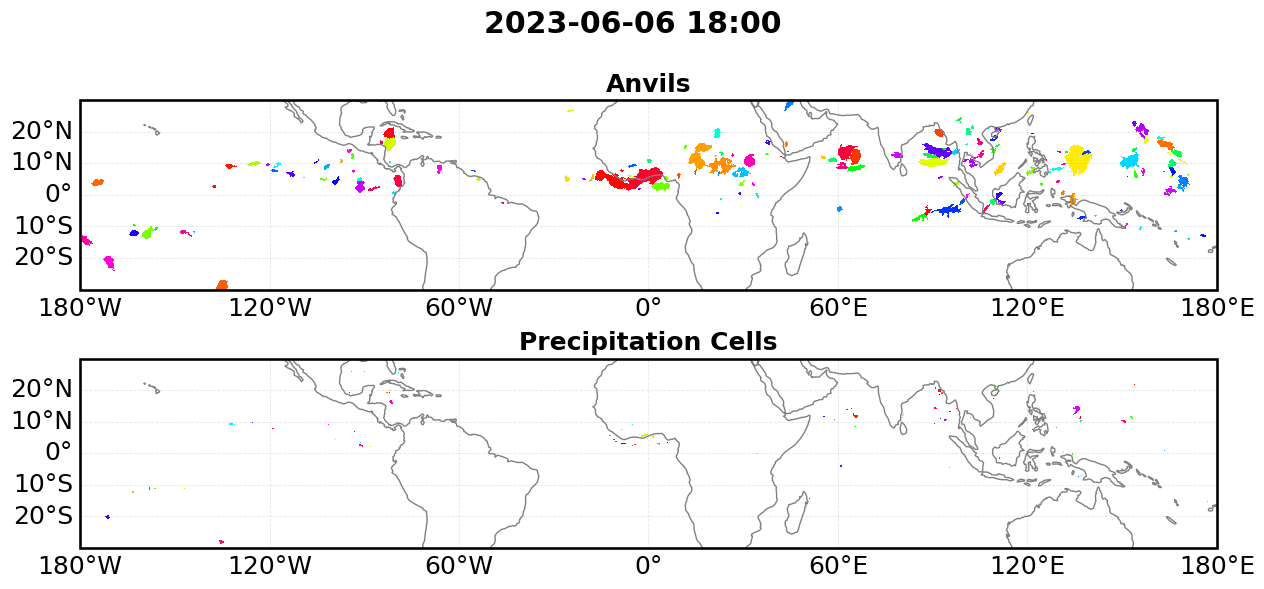

In [40]:
georegion = "global"
#plt.style.use('tex')
sns.set_context("talk")

fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 6),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

fig,axes[0], _ = plots_mapping.domain_plot_seg_mask(seg2d_anvil,cmap=cmap_anvil,norm = norm_anvil,
                                                    domain=  georegions[georegion],
                                                    title = f'Anvils', fig = fig, ax = axes[0])
fig,axes[1], _= plots_mapping.domain_plot_seg_mask(seg2d_cell,cmap=cmap_cell,norm = norm_cell,
                                                   domain=  georegions[georegion],
                                                   title = f'Precipitation Cells', fig = fig, ax = axes[1])

fig.suptitle(f"{date_title}", fontweight="bold")

plt.tight_layout()
plt.show()

In [41]:
if saveoutputs: 
    fig.savefig(os.path.join(plots_dir,f"quickplot_segmentation_OBS_combi_{georegion}_{param_tag}_{date}.pdf"),dpi=150, bbox_inches='tight')

# combi plot iwthfiltered anvils

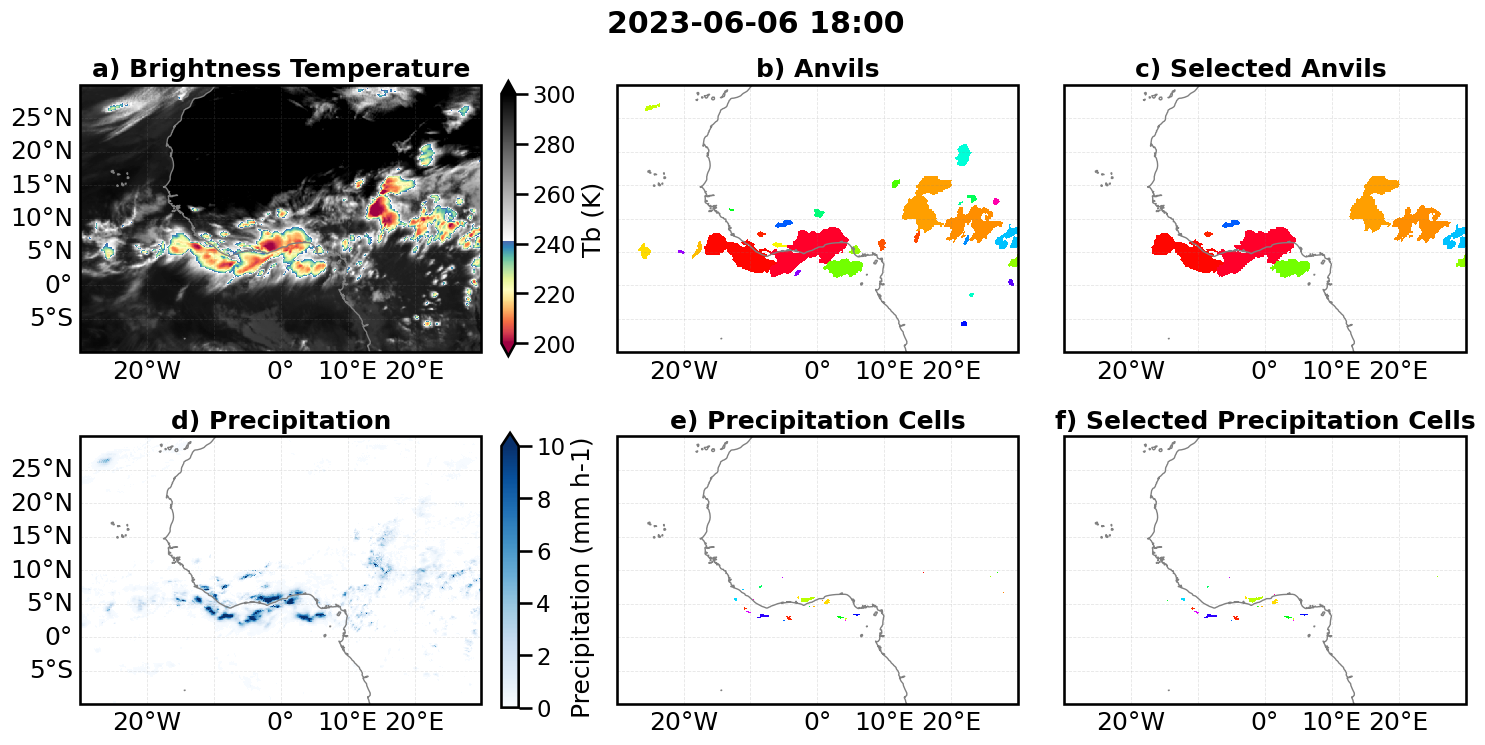

In [42]:
from matplotlib.colors import ListedColormap

bg_cmap = ListedColormap([
    (1, 1, 1, 0.0),   # 0 → fully transparent
    (0.75, 0.75, 0.75, 1.0)  # 1 → light grey (darker than before)
])

sns.set_context("talk")
#plt.style.use('tex')

# def georegion 
georegion = ["africa_0"]

#for georegion in  georegions.keys(): #georegion:
for georegion in georegion:
    if georegion == "global":
        continue

    lon_min, lon_max, lat_min, lat_max = georegions[georegion]
    lon_extent = lon_max - lon_min
    lat_extent = lat_max - lat_min

    fig_width = 15
    # account for ~10% width lost to colorbars on col 0
    effective_lon = lon_extent * 0.90
    fig_height = fig_width * (lat_extent / effective_lon) * (2 / 3)
    fig_height = max(5, min(fig_height, 20))

    # plot
    fig, axes = plt.subplots(
        2, 3,
        figsize=(fig_width, fig_height),
        subplot_kw={"projection": ccrs.PlateCarree()},
        constrained_layout = True
    )
    
    # tb image
    _, axes[0, 0], _ = plots_mapping.domain_plot_tb(tb, domain=georegions[georegion],left_grid_label=True,bottom_grid_label = True, title="a) Brightness Temperature", fig=fig, ax=axes[0, 0])
    # anvil seg
    _, axes[0, 1], _ = plots_mapping.domain_plot_seg_mask(seg2d_anvil, cmap=cmap_anvil,norm = norm_anvil,domain=georegions[georegion],left_grid_label=False,bottom_grid_label = True, title="b) Anvils", fig=fig, ax=axes[0, 1])
    # anvil seg
    _, axes[0, 2], _ = plots_mapping.domain_plot_seg_mask(seg2d_anvil_filtered,cmap=cmap_anvil,norm = norm_anvil, domain=georegions[georegion], left_grid_label=False,bottom_grid_label = True,
                                                            background=seg2d_anvil_bg,cmap_background=bg_cmap,#"Greys",
                                                            title="c) Selected Anvils ", fig=fig, ax=axes[0, 2])
    
    # precip image
    _, axes[1, 0], _ = plots_mapping.domain_plot_precip(precip,vmin = 0, vmax = 10, domain=georegions[georegion], left_grid_label=True,bottom_grid_label = True,title="d) Precipitation", fig=fig, ax=axes[1, 0])
    # precip seg
    _, axes[1, 1], _ = plots_mapping.domain_plot_seg_mask(seg2d_cell,cmap=cmap_cell,norm = norm_cell, domain=georegions[georegion],left_grid_label=False,bottom_grid_label = True, title="e) Precipitation Cells", fig=fig, ax=axes[1, 1])
    # precip seg
    _, axes[1, 2], _ = plots_mapping.domain_plot_seg_mask(seg2d_cell_filtered, cmap=cmap_cell,norm = norm_cell,domain=georegions[georegion], left_grid_label=False,bottom_grid_label = True,
                                                            background=seg2d_cell_bg,cmap_background=bg_cmap,#"Greys",
                                                            title="f) Selected Precipitation Cells", fig=fig, ax=axes[1, 2])
    
    fig.suptitle(f"{date_title}", fontweight="bold")
    
    # solve unequal subplot soizes due to colorbar
    dummy = plt.cm.ScalarMappable(cmap="Greys")
    cbar = fig.colorbar(dummy, ax=axes[0, 1], fraction=0.046, pad=0.04)
    cbar.ax.set_visible(False)
    cbar = fig.colorbar(dummy, ax=axes[1, 1], fraction=0.046, pad=0.04)
    cbar.ax.set_visible(False)
    cbar = fig.colorbar(dummy, ax=axes[0, 2], fraction=0.046, pad=0.04)
    cbar.ax.set_visible(False)
    cbar = fig.colorbar(dummy, ax=axes[1, 2], fraction=0.046, pad=0.04)
    cbar.ax.set_visible(False)

    #plt.tight_layout()
    if saveoutputs: 
        fig.savefig(os.path.join(plots_dir,f"quickplot_segmentation_OBS_combined_filtered_cells_{georegion}_{param_tag}_{date}.pdf"),dpi=150, bbox_inches='tight')
   
    fig.canvas.draw()

    plt.show()
    plt.close(fig)
   

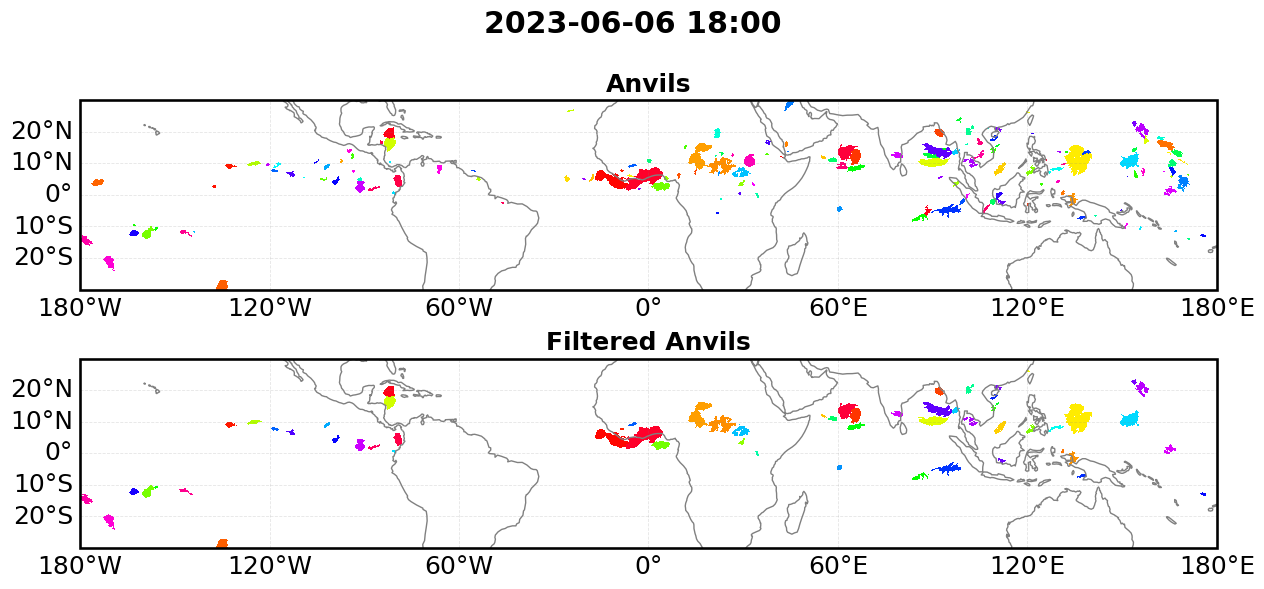

In [43]:
georegion = "global"
#plt.style.use('tex')
sns.set_context("talk")

fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 6),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

fig,axes[0], _ = plots_mapping.domain_plot_seg_mask(seg2d_anvil,cmap=cmap_anvil,norm = norm_anvil,
                                                    domain=  georegions[georegion],
                                                    title = f'Anvils', fig = fig, ax = axes[0])
fig,axes[1], _= plots_mapping.domain_plot_seg_mask(seg2d_anvil_filtered,cmap=cmap_anvil,norm = norm_anvil,
                                                   domain=  georegions[georegion],
                                                   title = f'Filtered Anvils', fig = fig, ax = axes[1])

fig.suptitle(f"{date_title}", fontweight="bold")

plt.tight_layout()
plt.show()

In [44]:
if saveoutputs: 
    fig.savefig(os.path.join(plots_dir,f"quickplot_segmentation_OBS_anvil_beforeandafter_{georegion}_{param_tag}_{date}.pdf"),dpi=150, bbox_inches='tight')